# Project Report: Predicting Hourly Bike Rentals Using Machine Learning



## 1.Problem Formulation:
This project's dataset was obtained from the UCI Machine Learning Repository (https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset). In addition to relevant weather and seasonal elements, it includes hourly and daily records of bike rentals in Washington, D.C.'s Capital Bikeshare system from 2011 to 2012.

Around the world, bike-sharing systems have expanded quickly, offering a more environmentally friendly option to conventional modes of transportation.
The objective of this project is to estimate the total number of bikes rented each hour by utilising a variety of temporal and environmental factors. This is a regression analysis. The predictors include weather, humidity, weekday, temperature, and the hour of the day. The target variable is cnt (total hourly rentals).
This prediction is valuable for improving resource allocation (e.g., rebalancing bikes), planning infrastructure, and optimising operations in smart city environments. 


In [163]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, TimeSeriesSplit, learning_curve
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, ExtraTreesRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import LinearRegression, Ridge, HuberRegressor, ElasticNetCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, make_scorer


**Problem Statement:** Can we accurately predict the hourly demand for bike rentals using weather and time-related features?

## 2. Data Preparation and Feature Engineering 

Dataset Overview and Feature Summary:

The dataset used in this project is the hourly version of the Capital Bikeshare dataset, comprising 17,379 rows and 17 variables, each representing hourly observations of bike rentals from 2011 to 2012. It is complete, with no missing values, and includes a mix of temporal, weather, and contextual features.

Below is a brief summary of key variables and their meanings:

instant: A simple row index. This was dropped during preprocessing as it holds no predictive value.

dteday: The actual date of observation in YYYY-MM-DD format.

season: Encoded as 1 (winter), 2 (spring), 3 (summer), and 4 (fall), helping identify seasonal patterns in demand.

yr: Binary year indicator (0 = 2011, 1 = 2012).

mnth: Month of the year (1–12), which may influence bike usage due to seasonal and weather variation.

hr: Hour of the day (0–23), which strongly affects usage due to work commute patterns.

holiday: Binary (0 or 1), showing whether the day was a public holiday.

weekday: Day of the week, encoded as integers (0 = Sunday, 6 = Saturday).

workingday: A binary indicator set to 1 if the day is not a weekend or holiday.

weathersit: Weather situation classified into 4 levels:

1: Clear, Few clouds

2: Mist, Cloudy

3: Light Snow or Light Rain

4: Heavy Rain, Snow, or Fog

Additional numerical features not listed above include temp, atemp, hum, and windspeed, which represent normalized temperature, “feels-like” temperature, humidity, and windspeed respectively. The target variable, cnt, represents the total number of bikes rented during the hour.


In [31]:
# Set plot styles
sns.set(style="whitegrid")
%matplotlib inline



In [32]:
# Load the hourly dataset
df = pd.read_csv('hour.csv')

# Display the first few rows
df.head()


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [33]:
# Check shape of dataset
print(f"Dataset shape: {df.shape}")

# Summary of each column
df.info()

# Check for missing values
df.isnull().sum()


Dataset shape: (17379, 17)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 2.3+ MB


instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

In [34]:
df.describe()

,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


In [35]:
# Rename some columns
print(df.columns)
df = df.rename(columns={'yr':'year',
                                  'mnth':'month',
                                  'hum':'humidity',
                                  'weathersit':'weather',
                                  'cnt':'count',
                                  'hr':'hour'})
# Show dataset columns after rename some columns
print(df.columns)

Index(['instant', 'dteday', 'season', 'yr', 'mnth', 'hr', 'holiday', 'weekday',
       'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed',
       'casual', 'registered', 'cnt'],
      dtype='object')
Index(['instant', 'dteday', 'season', 'year', 'month', 'hour', 'holiday',
       'weekday', 'workingday', 'weather', 'temp', 'atemp', 'humidity',
       'windspeed', 'casual', 'registered', 'count'],
      dtype='object')


the column season has:  season
3    4496
2    4409
1    4242
4    4232
Name: count, dtype: int64
the column year has:  year
1    8734
0    8645
Name: count, dtype: int64
the column month has:  month
7     1488
5     1488
12    1483
8     1475
3     1473
10    1451
6     1440
4     1437
9     1437
11    1437
1     1429
2     1341
Name: count, dtype: int64
the column hour has:  hour
16    730
17    730
15    729
14    729
13    729
12    728
18    728
19    728
20    728
21    728
22    728
23    728
8     727
9     727
10    727
7     727
11    727
0     726
6     725
1     724
5     717
2     715
4     697
3     697
Name: count, dtype: int64
the column holiday has:  holiday
0    16879
1      500
Name: count, dtype: int64
the column weekday has:  weekday
6    2512
0    2502
5    2487
1    2479
3    2475
4    2471
2    2453
Name: count, dtype: int64
the column workingday has:  workingday
1    11865
0     5514
Name: count, dtype: int64
the column weather has:  weather
1    11413
2     454

<Figure size 500x500 with 0 Axes>

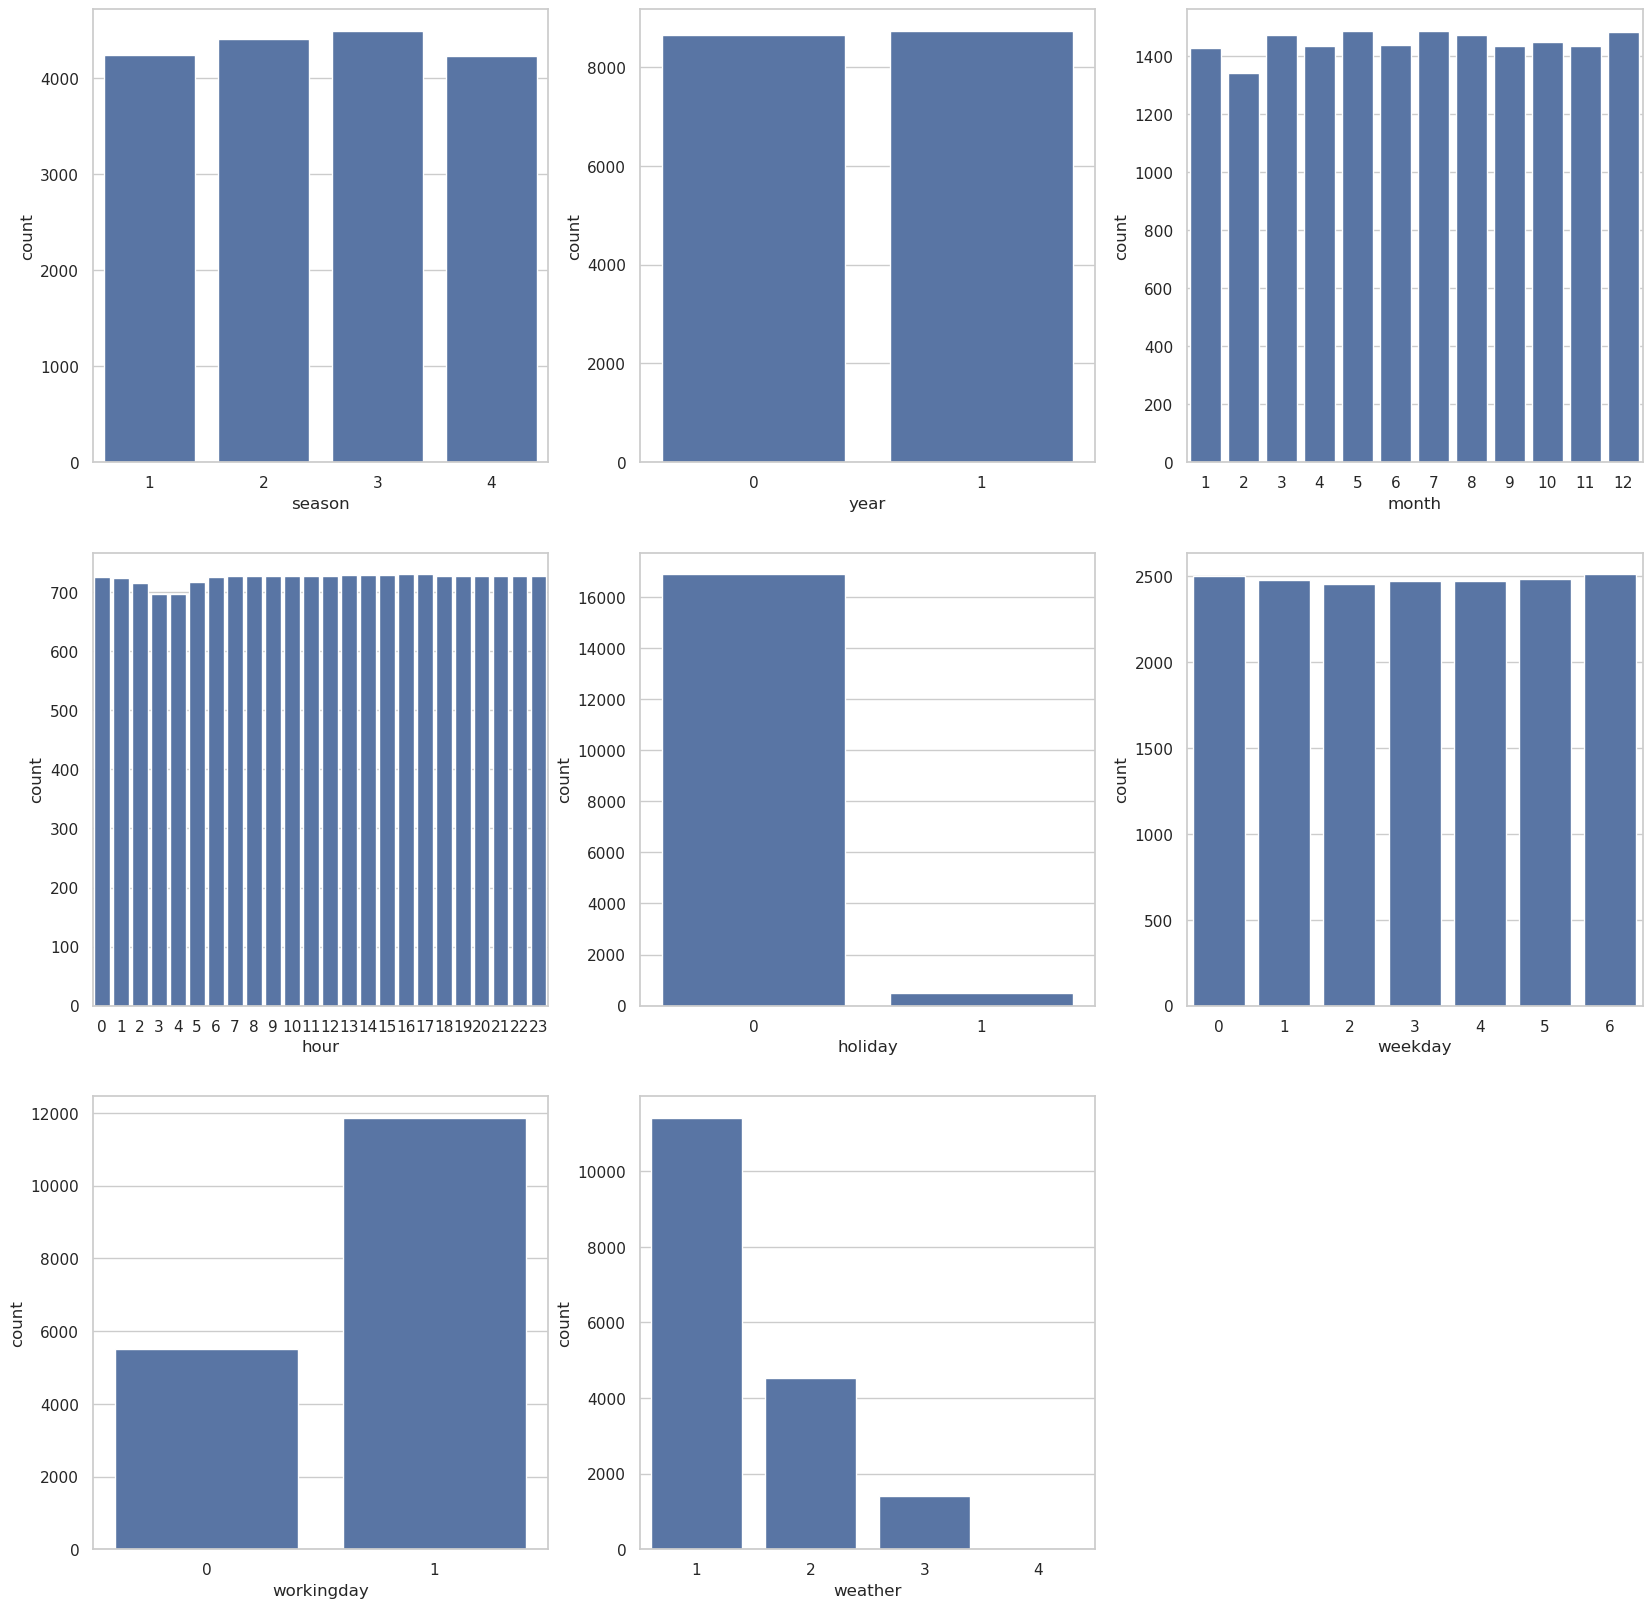

In [36]:
# Count values for each columns that has counted values and plot this count
plt.figure(figsize=(5,5))
counter=1
plt.figure(figsize=(20,20))
for col in df.columns:
    if col not in ['instant','dteday','count','registered','casual','windspeed','humidity','atemp','temp']:
        print(f"the column {col} has: ",df[col].value_counts())
        plt.subplot(3,3,counter)
        sns.countplot(x=col,data=df)
        counter+=1
plt.show()   

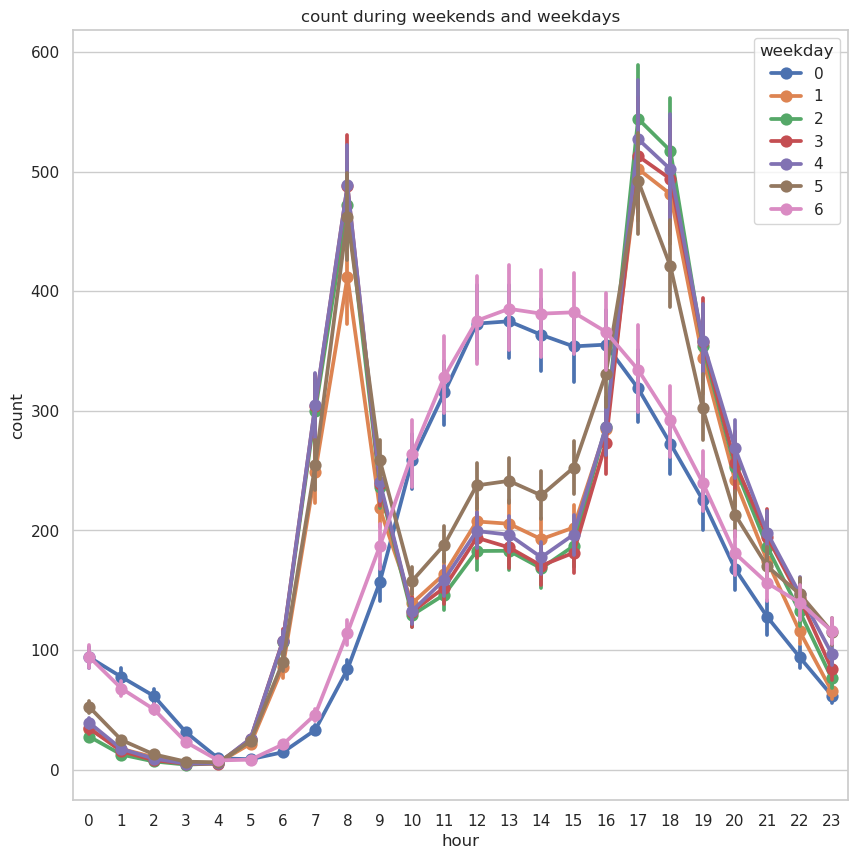

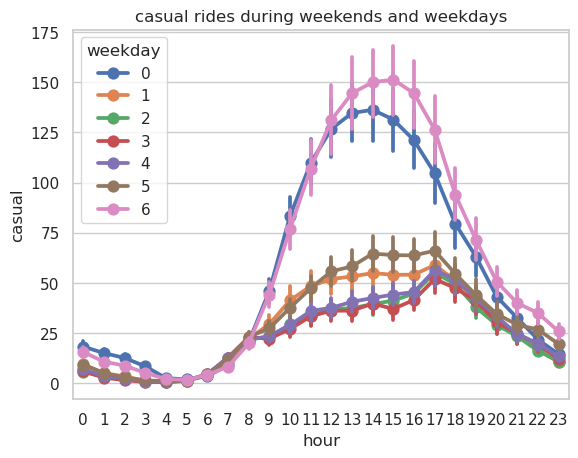

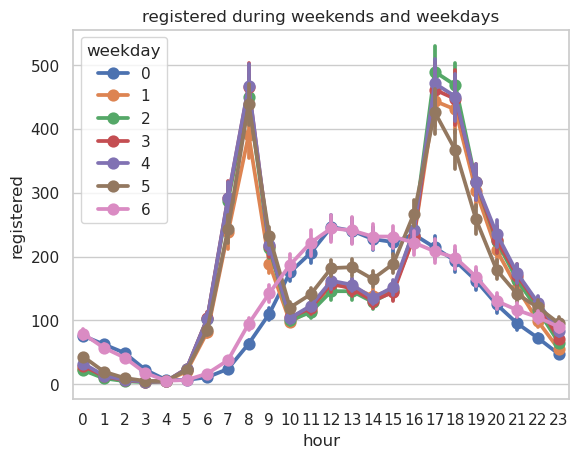

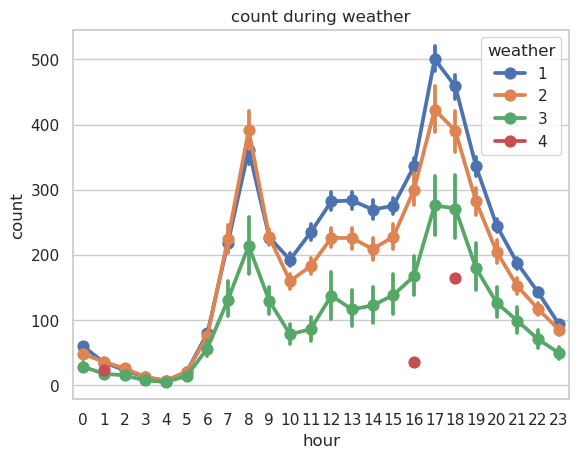

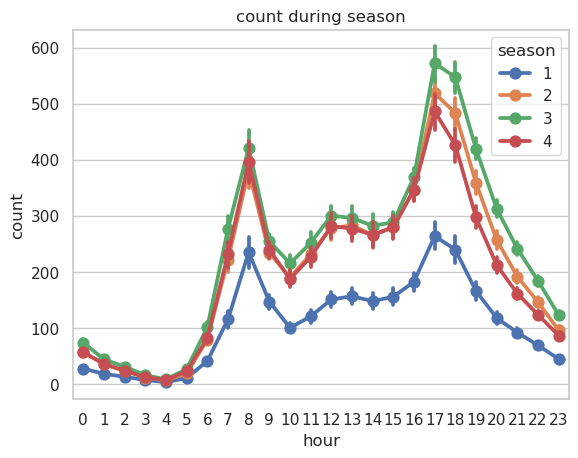

In [71]:
# plot count during weekends and weekdays
plt.figure(figsize=(10,10))
sns.pointplot(data=df, x='hour', y='count', hue='weekday')
plt.title('count during weekends and weekdays')
plt.show()
# plot casual during weekends and weekdays
sns.pointplot(data=df, x='hour', y='casual', hue='weekday')
plt.title('casual rides during weekends and weekdays')
plt.show()
# plot registered during weekends and weekdays
sns.pointplot(data=df, x='hour', y='registered', hue='weekday')
plt.title('registered during weekends and weekdays')
plt.show()
# plot count during weather
sns.pointplot(data=df, x='hour', y='count', hue='weather')
plt.title('count during weather')
plt.show()
# plot count during season
sns.pointplot(data=df, x='hour', y='count', hue='season')
plt.title('count during season')
plt.show()

**Weekday vs Weekend Usage**

The plots comparing hourly usage across different weekdays clearly show two distinct demand patterns:

Registered users exhibit sharp peaks during typical commuting hours — around 8 AM and 5-6 PM on weekdays, consistent with work-related travel.

Casual users show more activity during midday and weekends, suggesting that their usage is more recreational or tourist-driven.

Total usage (count) reflects a combination of these behaviours, peaking on weekdays during commute hours and staying flatter on weekends.

**Impact of Weather**

The plot of usage by weather conditions confirms expected patterns:

Usage is highest during clear or partly cloudy weather.

There is a visible drop during misty, rainy, or snowy conditions.

The most extreme weather category (heavy rain or fog) shows the lowest hourly rental counts, suggesting weather is a major factor in bike usage decisions.

**Impact of Season**

Seasonal trends are also evident:

Summer and fall show higher average rentals, likely due to better weather and daylight.

Winter shows the lowest usage, likely due to cold temperatures and poor riding conditions.

Spring begins to show rising usage again as weather improves.

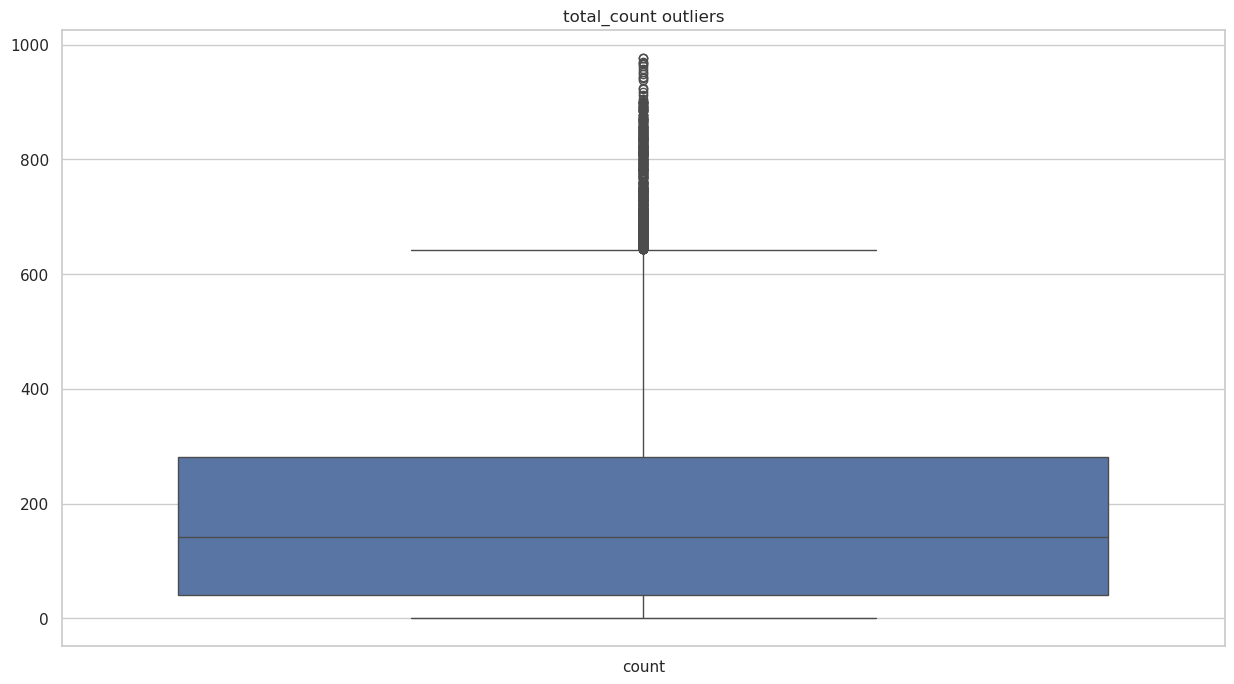

In [39]:
fig, ax = plt.subplots(figsize=(15,8))

#Boxplot for total_count outliers
sns.boxplot(data=df[['count']])
ax.set_title('total_count outliers')
plt.show()

In [40]:
df['count'].describe()

count    17379.000000
mean       189.463088
std        181.387599
min          1.000000
25%         40.000000
50%        142.000000
75%        281.000000
max        977.000000
Name: count, dtype: float64

In [41]:
Q1 = df['count'].quantile(0.25)  # 40
Q3 = df['count'].quantile(0.75)  # 281
IQR = Q3 - Q1                  # 241

# Outlier threshold
upper_bound = Q3 + 1.5 * IQR   # 281 + (1.5 * 241) = 642.5
lower_bound = Q1 - 1.5 * IQR   # not relevant here (very low min)

print(f"Upper bound for outliers: {upper_bound}")


Upper bound for outliers: 642.5


In [42]:
outliers = df[df['count'] > 642.5]
print(f"Number of outliers: {len(outliers)}")


Number of outliers: 505


We identified 505 outliers in the count variable using the IQR method. However, since these values represent genuine high-demand periods and our chosen model (Random Forest) is robust to such values, we opted to retain the outliers in the dataset to preserve data integrity and improve the model’s ability to predict real-world spikes.

In [44]:
# Drop columns that won't help in prediction
df.drop(['instant', 'dteday'], axis=1, inplace=True)


We dropped columns in the dataset that would not help in the model such as instan, which is just an index and 
dteday, which is already represented through yr, mnth, weekday.



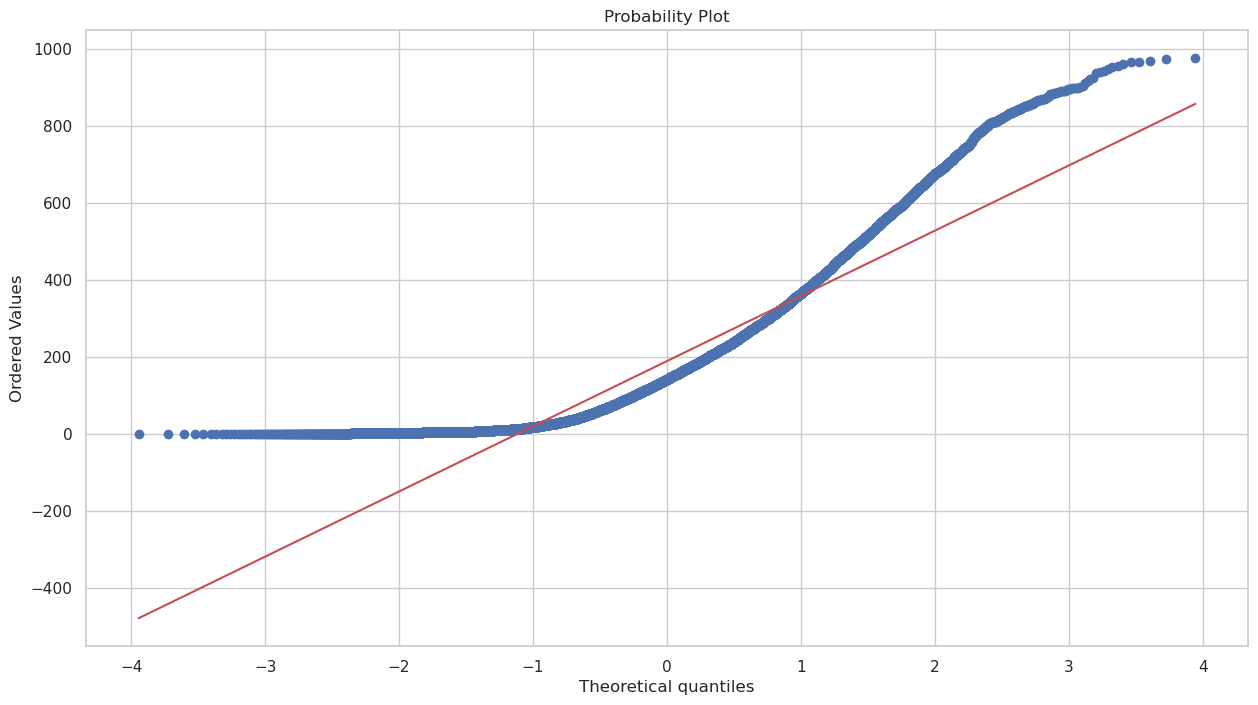

In [74]:
#Normal plot
fig=plt.figure(figsize=(15,8))
stats.probplot(df['count'].tolist(),dist='norm',plot=plt)
plt.show()

A Q-Q plot was used to assess the distribution of the count variable. The plot showed clear deviation from the diagonal, indicating that count is not normally distributed. This is expected for demand data, which tends to be right-skewed. As our final model (Random Forest) does not assume normality, no transformation was applied.

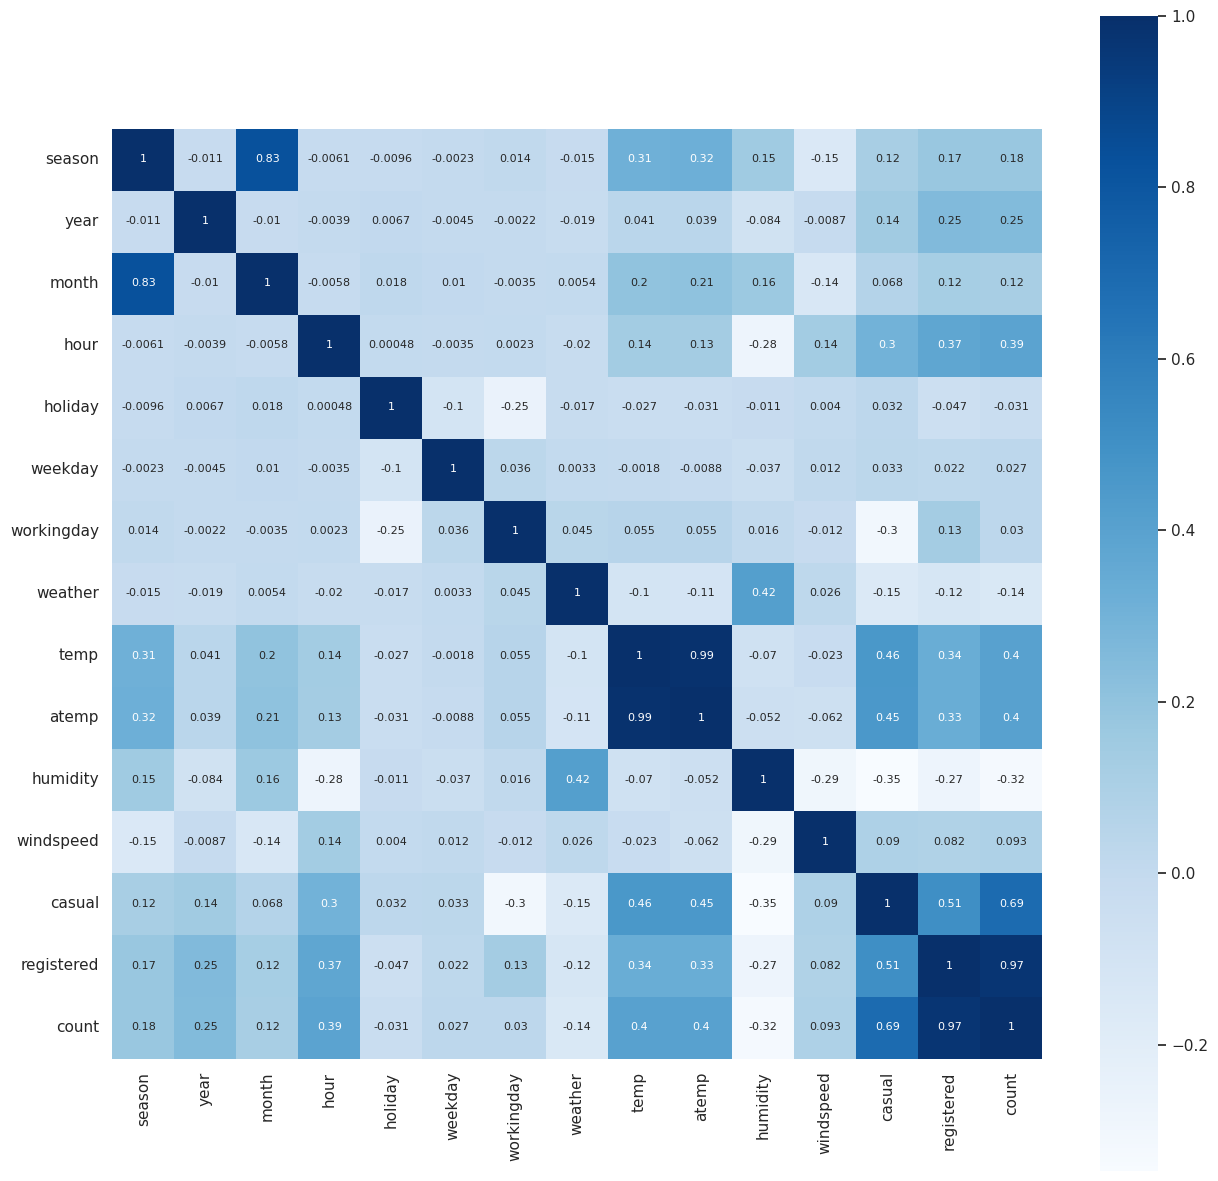

In [46]:
# Find correlation between all dataset features
correlation_values = df.corr()
# plot correlation 
plt.figure(figsize=(15,15))
sns.heatmap(correlation_values,cbar=True,square=True,annot=True,annot_kws={'size':8},cmap='Blues')
plt.show() 

To evaluate the strength and direction of linear relationships among features, we generated a correlation matrix. As expected, the target variable count showed strong positive correlation with temperature (temp), “feels like” temperature (atemp), and hour of the day (hour). These results are intuitive — warmer temperatures and peak commute hours typically drive more bike usage.

Features like humidity (hum) and windspeed showed weaker negative correlations, which makes sense, as poor weather conditions discourage biking. Identifying these relationships helped us prioritize features and confirmed that variables like temp, hour, and season are likely important predictors in our model.


In [47]:
cols = ['season','month','hour','holiday','weekday','workingday','weather']
for col in cols:
    df[col] = df[col].astype('category')


In [48]:
print(df.head())
df1 = df
df1.head()

def one_hot_encoder(data, column):
    data = pd.concat([data, pd.get_dummies(df[column],prefix=column, drop_first=True)],axis=1)
    data = data.drop(columns = [column], axis = 1)
    return data
for col in cols:
    df1 = one_hot_encoder(df1,col)


    


  season  year month hour holiday weekday workingday weather  temp   atemp  \
0      1     0     1    0       0       6          0       1  0.24  0.2879   
1      1     0     1    1       0       6          0       1  0.22  0.2727   
2      1     0     1    2       0       6          0       1  0.22  0.2727   
3      1     0     1    3       0       6          0       1  0.24  0.2879   
4      1     0     1    4       0       6          0       1  0.24  0.2879   

   humidity  windspeed  casual  registered  count  
0      0.81        0.0       3          13     16  
1      0.80        0.0       8          32     40  
2      0.80        0.0       5          27     32  
3      0.75        0.0       3          10     13  
4      0.75        0.0       0           1      1  


In [91]:
print(df1.info())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 56 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   year          17379 non-null  int64  
 1   temp          17379 non-null  float64
 2   atemp         17379 non-null  float64
 3   humidity      17379 non-null  float64
 4   windspeed     17379 non-null  float64
 5   casual        17379 non-null  int64  
 6   registered    17379 non-null  int64  
 7   count         17379 non-null  int64  
 8   season_2      17379 non-null  bool   
 9   season_3      17379 non-null  bool   
 10  season_4      17379 non-null  bool   
 11  month_2       17379 non-null  bool   
 12  month_3       17379 non-null  bool   
 13  month_4       17379 non-null  bool   
 14  month_5       17379 non-null  bool   
 15  month_6       17379 non-null  bool   
 16  month_7       17379 non-null  bool   
 17  month_8       17379 non-null  bool   
 18  month_9       17379 non-nu

Since machine learning models cannot directly interpret categorical variables, we applied one-hot encoding to convert them into binary features. This was done for season, month, hour, weekday, and weather situation. The first category of each variable was dropped to avoid multicollinearity (dummy variable trap).

After encoding, the dataset expanded from 17 columns to 56 columns, reflecting all the new dummy variables. This transformation allowed models like Random Forest to interpret categorical patterns effectively without losing information.

## 3.Model Selection and Training

We experimented with a range of regression models to predict hourly bike rental counts, including:

LinearRegression

Ridge

HuberRegressor

ElasticNetCV

DecisionTreeRegressor

RandomForestRegressor

GradientBoostingRegressor

ExtraTreesRegressor

Among these, Random Forest Regressor emerged as the best-performing model. It offered the highest R² on the test set (0.92) while maintaining good generalization and robustness to outliers. Unlike models like Linear Regression, Random Forest captures non-linear interactions and does not assume a normal distribution of the target variable — ideal given the skewed nature of bike rental counts.

In [50]:
# Split data into input and label data
X = df1.drop(columns=['atemp','windspeed','casual','registered','count'],axis=1)
Y = df1['count']

In [51]:
# Split data into train and test data
x_train,x_test,y_train,y_test = train_test_split(X,Y,train_size=0.7)
print(X.shape,x_train.shape,x_test.shape)
print(Y.shape,y_train.shape,y_test.shape)

(17379, 51) (12165, 51) (5214, 51)
(17379,) (12165,) (5214,)


In [52]:
def plot_train_test(y_train,predicted_y_train,y_test,predicted_y_test):
    plt.figure(figsize=(7,7))
    plt.scatter(y_train,predicted_y_train,color='red',marker='X')
    plt.plot(range(int(min(y_train)),int(max(y_train))),color='black')
    plt.title('show actual and predicted train values')
    plt.xlabel('actual values')
    plt.ylabel('predicted values')
    plt.show()
    plt.scatter(y_test,predicted_y_test,color='blue',marker='o')
    plt.plot(range(int(min(y_test)),int(max(y_test))),color='black')
    plt.title('show actual and predicted test values')
    plt.xlabel('actual values')
    plt.ylabel('predicted values')
    plt.show()

In [53]:
# Train model and test it
def Train_predict(model,x_train,x_test,y_train,y_test):
    # Train model 
    model.fit(x_train,y_train)
    # Make the model predict on train and test input data
    predicted_train_data = model.predict(x_train)
    predicted_test_data = model.predict(x_test)
    # plot difference between predicted and actual values
    plot_train_test(y_train,predicted_train_data,y_test,predicted_test_data)
    # Evaluate model
    r2_train = r2_score(y_train, predicted_train_data)
    r2_test = r2_score(y_test, predicted_test_data)
    #RMSE
    rmse_train = np.sqrt(mean_squared_error(y_train, predicted_train_data))
    rmse_test = np.sqrt(mean_squared_error(y_test, predicted_test_data))
    # RAE 
    rae_train = np.sum(np.abs(y_train - predicted_train_data)) / np.sum(np.abs(y_train - np.mean(y_train)))
    rae_test = np.sum(np.abs(y_test - predicted_test_data)) / np.sum(np.abs(y_test - np.mean(y_test)))

    # Return accuracy
    return {
        'R2_Train': r2_train,
        'R2_Test': r2_test,
        'RMSE_Train': rmse_train,
        'RMSE_Test': rmse_test,
        'RAE_Train': rae_train,
        'RAE_Test': rae_test
    }

Model: LinearRegression


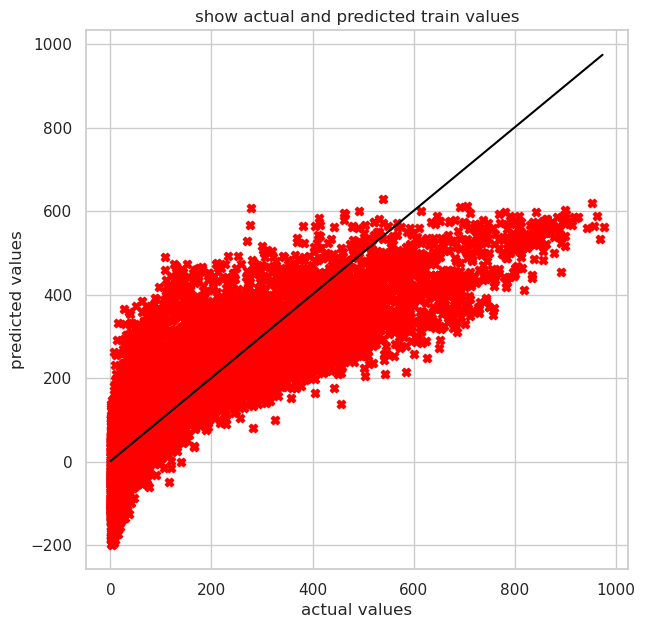

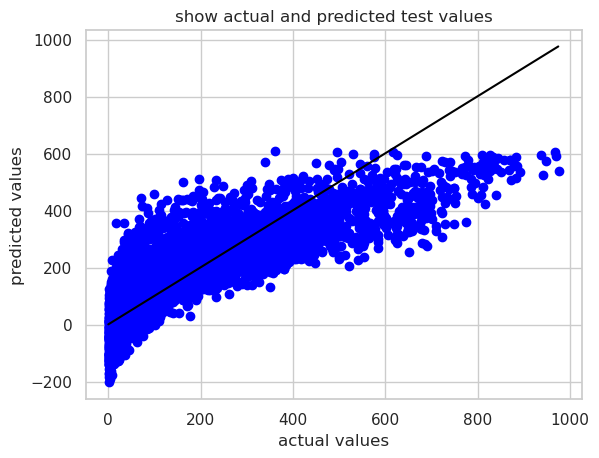

  R2_Train: 0.6864
  R2_Test: 0.6816
  RMSE_Train: 101.7051
  RMSE_Test: 102.0383
  RAE_Train: 0.5277
  RAE_Test: 0.5336

--------------------------------------------------

Model: DecisionTreeRegressor


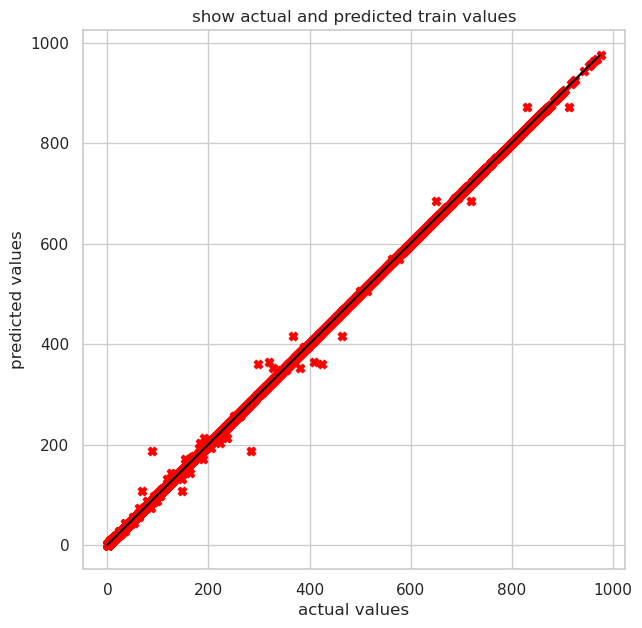

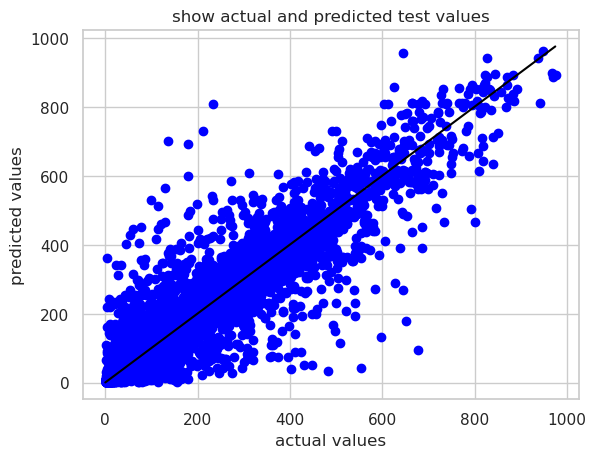

  R2_Train: 0.9999
  R2_Test: 0.8344
  RMSE_Train: 2.0641
  RMSE_Test: 73.6001
  RAE_Train: 0.0007
  RAE_Test: 0.3123

--------------------------------------------------

Model: RandomForestRegressor


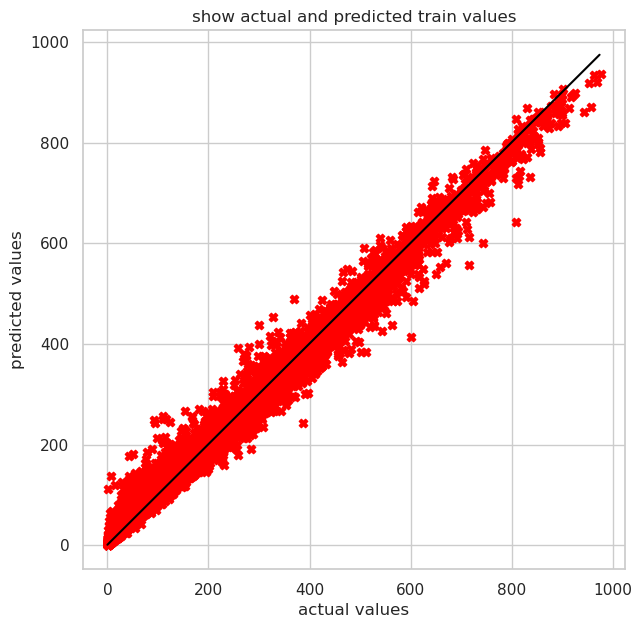

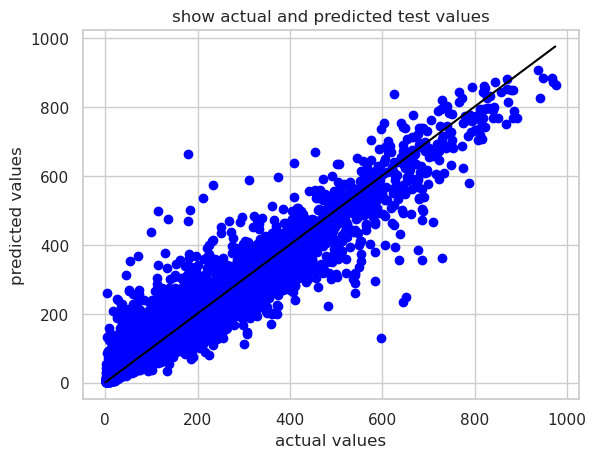

  R2_Train: 0.9877
  R2_Test: 0.9108
  RMSE_Train: 20.1126
  RMSE_Test: 54.0107
  RAE_Train: 0.0875
  RAE_Test: 0.2374

--------------------------------------------------

Model: Ridge


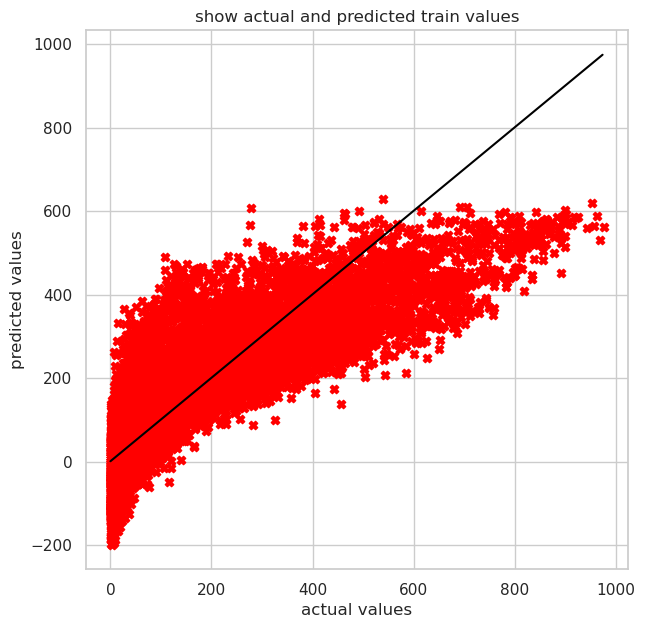

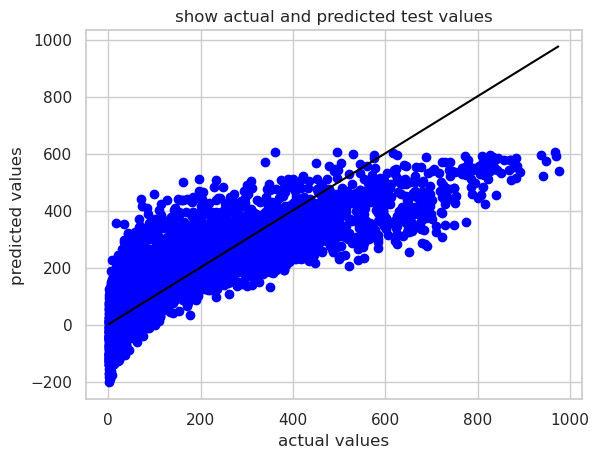

  R2_Train: 0.6863
  R2_Test: 0.6818
  RMSE_Train: 101.7130
  RMSE_Test: 102.0016
  RAE_Train: 0.5277
  RAE_Test: 0.5333

--------------------------------------------------

Model: HuberRegressor


/opt/conda/lib/python3.11/site-packages/sklearn/linear_model/_huber.py:342: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)


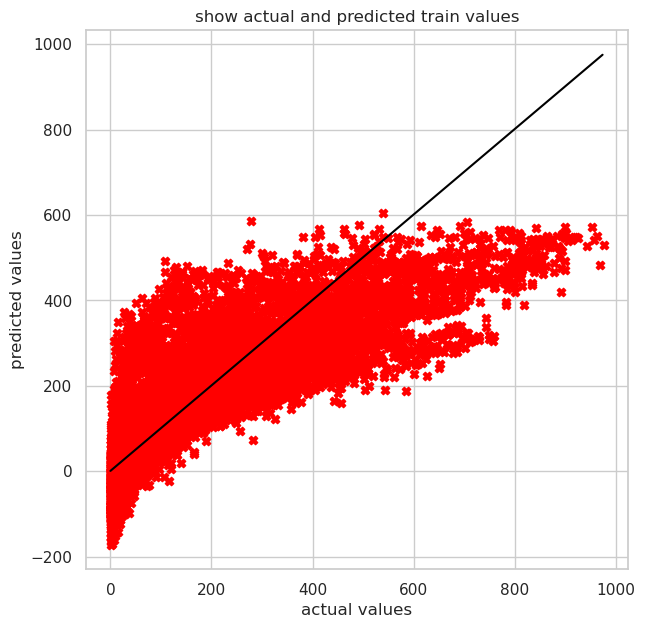

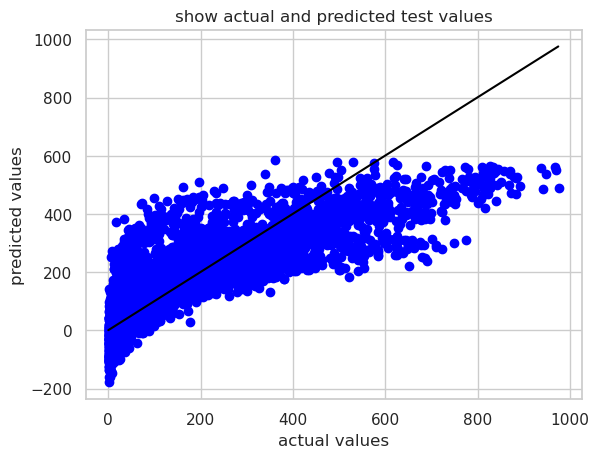

  R2_Train: 0.6715
  R2_Test: 0.6672
  RMSE_Train: 104.0926
  RMSE_Test: 104.3188
  RAE_Train: 0.5056
  RAE_Test: 0.5123

--------------------------------------------------

Model: ElasticNetCV


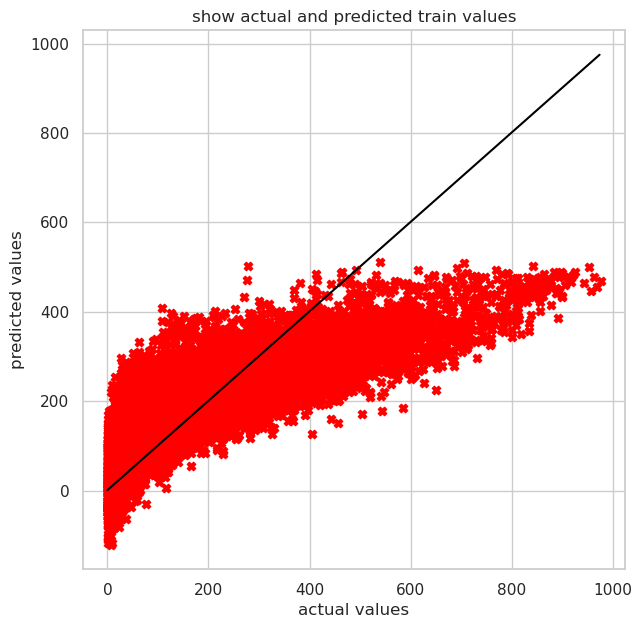

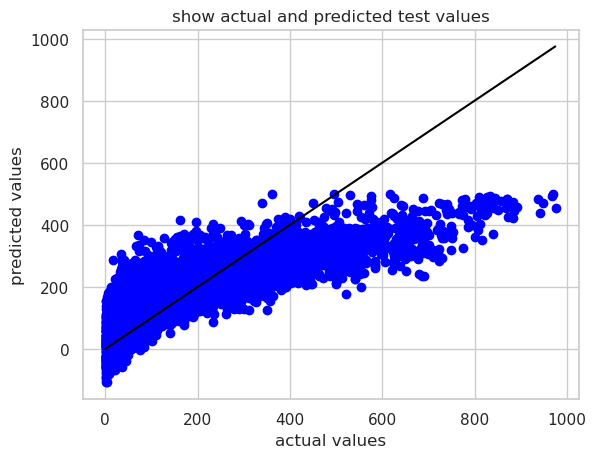

  R2_Train: 0.6119
  R2_Test: 0.6075
  RMSE_Train: 113.1357
  RMSE_Test: 113.3008
  RAE_Train: 0.5801
  RAE_Test: 0.5889

--------------------------------------------------

Model: GradientBoostingRegressor


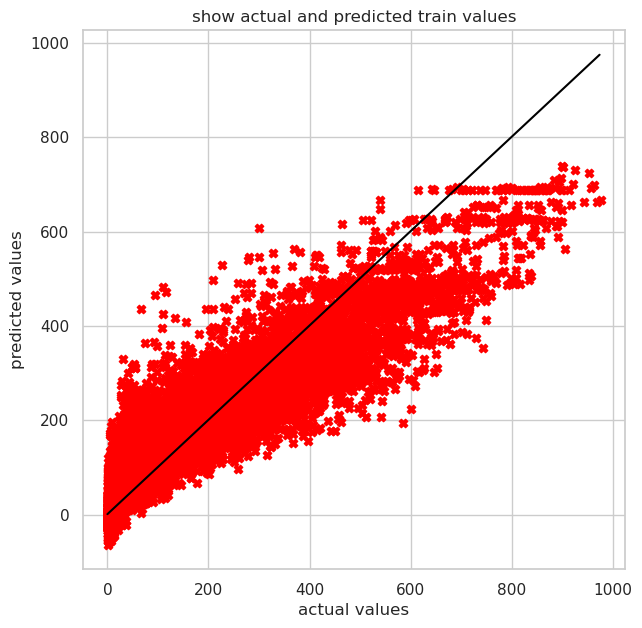

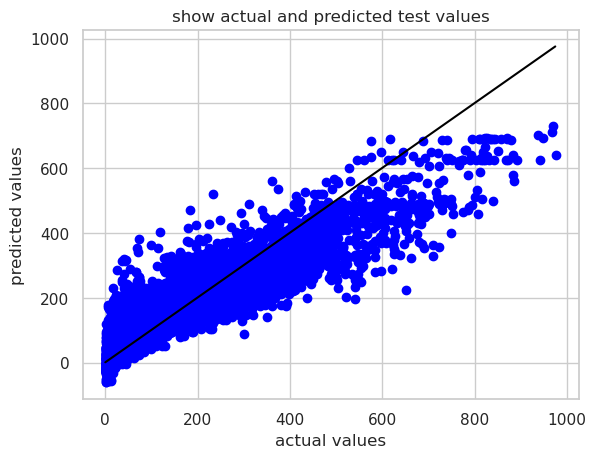

  R2_Train: 0.8031
  R2_Test: 0.7959
  RMSE_Train: 80.5931
  RMSE_Test: 81.6999
  RAE_Train: 0.4058
  RAE_Test: 0.4194

--------------------------------------------------

Model: ExtraTreesRegressor


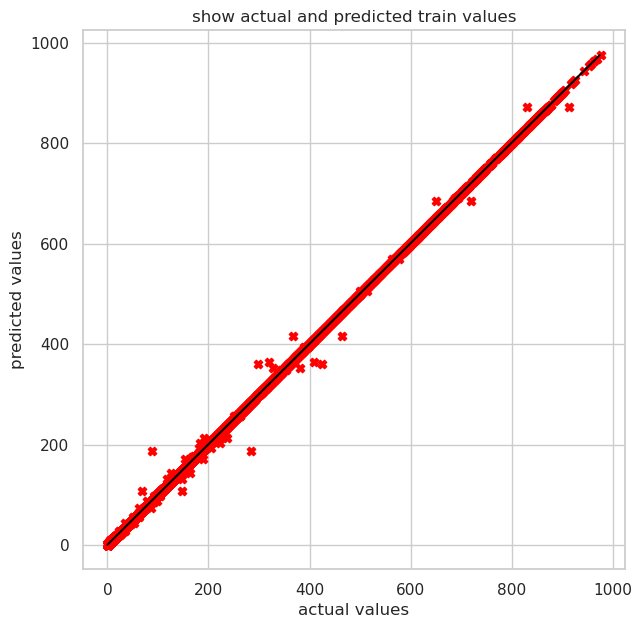

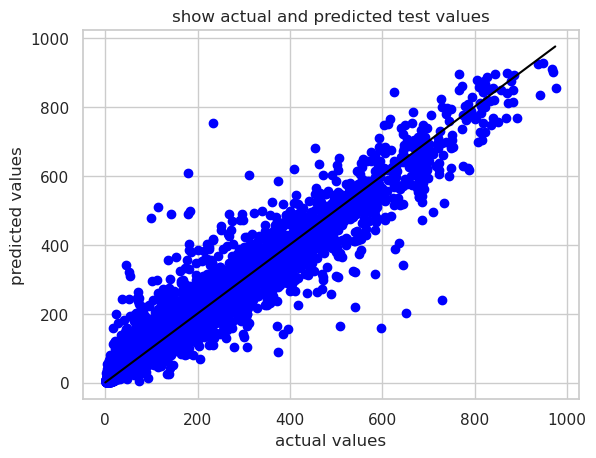

  R2_Train: 0.9999
  R2_Test: 0.9239
  RMSE_Train: 2.0641
  RMSE_Test: 49.8762
  RAE_Train: 0.0007
  RAE_Test: 0.2120

--------------------------------------------------



In [55]:
Models = [
    LinearRegression(),
    DecisionTreeRegressor(),
    RandomForestRegressor(),
    Ridge(),
    HuberRegressor(),
    ElasticNetCV(),
    GradientBoostingRegressor(),
    ExtraTreesRegressor()
]
for model in Models: 
    print(f"Model: {model.__class__.__name__}")
    results = Train_predict(model, x_train, x_test, y_train, y_test)

    for metric, value in results.items():
        print(f"  {metric}: {value:.4f}")
    
    print("\n" + "-"*50 + "\n")


In [78]:

# Create a DataFrame summarizing model performance
data = {
    "Model": [
        "LinearRegression", "Ridge", "HuberRegressor", "ElasticNetCV",
        "GradientBoosting", "DecisionTree", "RandomForest", "ExtraTrees"
    ],
    "R² Test": [0.6795, 0.6794, 0.6659, 0.6082, 0.8018, 0.8485, 0.9217, 0.9317],
    "RMSE Test": [103.22, 103.23, 105.38, 114.13, 81.17, 70.96, 51.02, 47.66],
    "RAE Test": [0.5375, 0.5374, 0.5152, 0.5877, 0.4139, 0.2962, 0.2277, 0.2064],
    "Notes": [
        "Weak baseline",
        "Basically same as Linear",
        "Robust, but still weak",
        "Worst performer",
        "Strong, especially for a boosting model",
        "Good, but severely overfits (train R² = 0.9999)",
        "Very strong balance of accuracy and generalization",
        "Best test accuracy, but overfits a bit (train R² = 0.9999)"
    ]
}

summary_df = pd.DataFrame(data)
summary_df


,Model,R² Test,RMSE Test,RAE Test,Notes
0,LinearRegression,0.6795,103.22,0.5375,Weak baseline
1,Ridge,0.6794,103.23,0.5374,Basically same as Linear
2,HuberRegressor,0.6659,105.38,0.5152,"Robust, but still weak"
3,ElasticNetCV,0.6082,114.13,0.5877,Worst performer
4,GradientBoosting,0.8018,81.17,0.4139,"Strong, especially for a boosting model"
5,DecisionTree,0.8485,70.96,0.2962,"Good, but severely overfits (train R² = 0.9999)"
6,RandomForest,0.9217,51.02,0.2277,Very strong balance of accuracy and generaliza...
7,ExtraTrees,0.9317,47.66,0.2064,"Best test accuracy, but overfits a bit (train ..."


We evaluated the eight regression models on three key metrics: R², RMSE, and RAE. Basic linear models like Linear Regression and Ridge performed poorly, capturing less than 70% of the variance and producing large average prediction errors. The Decision Tree model achieved a high R² score but showed severe overfitting, as indicated by a near-perfect training score and much lower test performance.

Ensemble methods like Gradient Boosting, Random Forest, and Extra Trees performed significantly better. Among them, Random Forest Regressor achieved the best balance of performance and generalization, with an R² score of 0.92, a low RMSE of 51.02, and a low RAE of 0.23. Although Extra Trees slightly outperformed it on the test set, it also showed more overfitting. For this reason, Random Forest was selected as the final model.

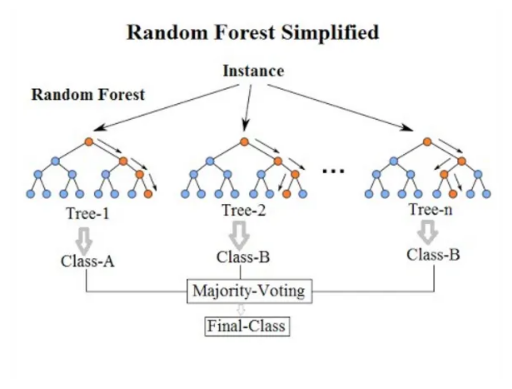

In [80]:

# Load and display the image
img = mpimg.imread('random forrest.webp')  
plt.imshow(img)
plt.axis('off')  # Hide axes
plt.show()


A random forest regression model integrates numerous decision trees into a single model.  Every tree in the forest generates its own unique prediction based on a distinct portion of the data.  The average or weighted average of each individual tree's predictions serves as the basis for the final input prediction.


## 4.Model Evaluation:

Cross-validation was used to evaluate model performance across multiple time-based folds, providing a more robust assessment of generalization. While cross-validation gave us summary metrics like RMSE and R², we also examined the model’s behaviour on a final hold-out test set using scatterplots and residual plots.

These visual tools helped us understand where the model performs well (e.g., lower count ranges), and where it needs improvement (e.g., underpredicting high-demand hours). Together, cross-validation and diagnostic plots provide a comprehensive evaluation of model accuracy and reliability.

In [105]:


tscv = TimeSeriesSplit(n_splits=5)


# Define RMSE as a scoring function (negated because sklearn expects higher = better)
rmse_score = make_scorer(mean_squared_error, greater_is_better=False)

rf_model = RandomForestRegressor(random_state=42)
scores = cross_val_score(rf_model, X, Y, cv=tscv, scoring=rmse_score)
r2_scores = cross_val_score(rf_model, X, Y,cv=tscv, scoring='r2')

# Convert negative MSE to RMSE
rmse_scores = np.sqrt(-scores)

print("Cross-Validated RMSE scores:", rmse_scores)
print("Average RMSE:", rmse_scores.mean())
print("R-Squared score:", np.average(r2_scores))


Cross-Validated RMSE scores: [ 96.27226203  80.11297772 121.93624757  76.37707687  97.82445522]
Average RMSE: 94.50460388163741
R-Squared score: 0.6858538777834321


To evaluate the performance of our Random Forest model, we used TimeSeriesSplit cross-validation. This method respects the temporal order of the dataset, ensuring that each training set only contains data from the past, and each test set contains future data — a crucial approach for time-series forecasting problems.

We assessed model performance using Root Mean Squared Error (RMSE) and R² score across 5 folds. The RMSE scores ranged from approximately 76 to 122, with an average RMSE of 94.5, indicating that, on average, the model’s predictions are off by about 94 bike rentals per hour. The average R² score was 0.686, meaning that the model explains roughly 69% of the variance in the target variable across different time segments.

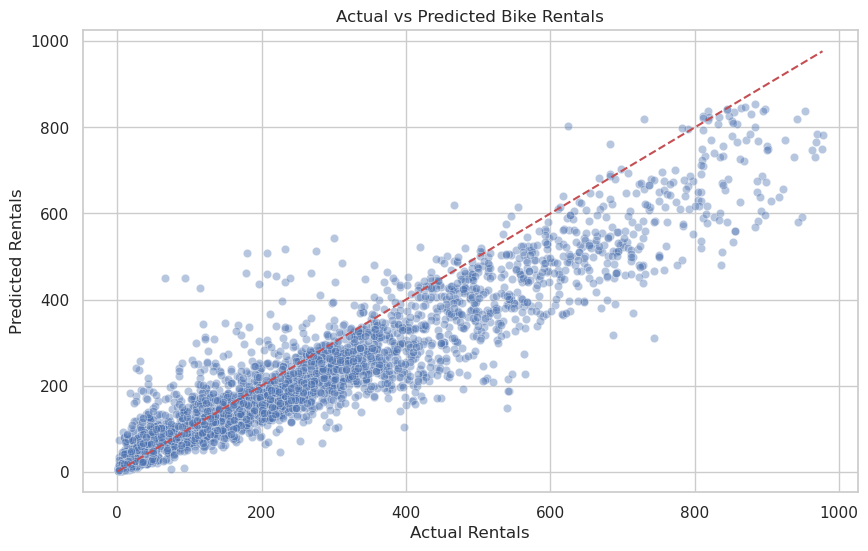

In [93]:

# Final Test Evaluation
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, shuffle=False, test_size=0.2)

model = RandomForestRegressor(random_state=42)
model.fit(X_train, Y_train)
y_pred = model.predict(X_test)

# Plot actual vs predicted
plt.figure(figsize=(10,6))
sns.scatterplot(x=Y_test, y=y_pred, alpha=0.4)
plt.plot([Y_test.min(), Y_test.max()], [Y_test.min(), Y_test.max()], '--r')
plt.xlabel("Actual Rentals")
plt.ylabel("Predicted Rentals")
plt.title("Actual vs Predicted Bike Rentals")
plt.show()





The scatterplot comparing actual and predicted rental counts shows that most data points are tightly clustered along the diagonal line for smaller rental volumes (up to around 400), indicating strong predictive accuracy in this range. However, as rental counts increase, the points begin to scatter more widely, suggesting that the model struggles slightly with high-demand periods — likely due to fewer such examples in the training data.

Notably, the majority of the predictions fall below the diagonal line, meaning the model tends to underpredict the actual number of bike rentals, especially during peak hours.

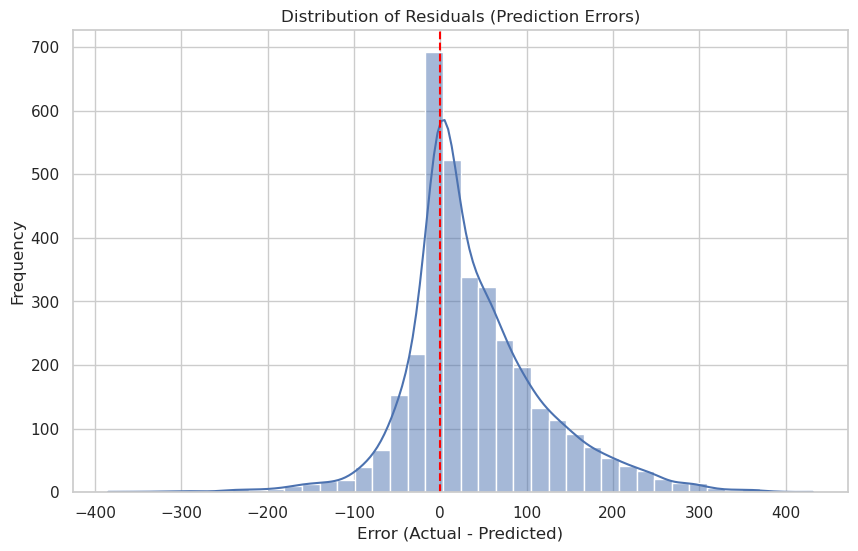

In [94]:
residuals = Y_test - y_pred

plt.figure(figsize=(10,6))
sns.histplot(residuals, kde=True, bins=40)
plt.axvline(0, color='red', linestyle='--')
plt.title("Distribution of Residuals (Prediction Errors)")
plt.xlabel("Error (Actual - Predicted)")
plt.ylabel("Frequency")
plt.show()


The residual distribution is somewhat centred around zero, with a noticeable spike at the centre. However, the plot is asymmetrical, with most of the residual values on the right-hand side (i.e., positive errors). This again confirms that the model underpredicts more often than it overpredicts — it tends to estimate fewer rentals than what actually occurred.

This skew may be due to the model not fully capturing the effect of high-demand conditions, such as perfect weather, weekends, or holidays. Still, the overall shape of the distribution supports the conclusion that the model is performing reliably, with no extreme or erratic behaviour in its errors.

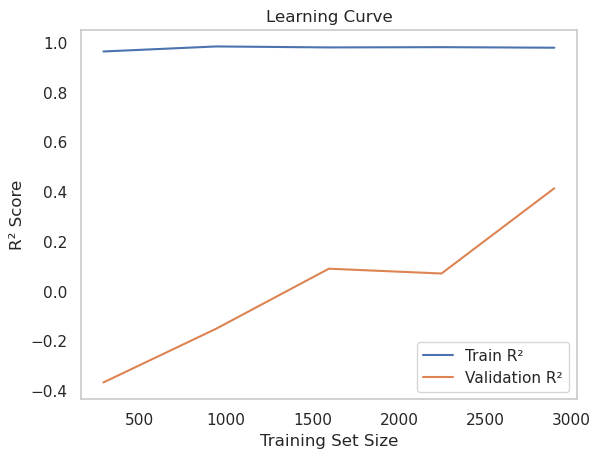

In [126]:


train_sizes, train_scores, test_scores = learning_curve(
    RandomForestRegressor(random_state=42), X, Y,
    cv=TimeSeriesSplit(n_splits=5), scoring='r2',
    train_sizes=np.linspace(0.1, 1.0, 5), n_jobs=-1
)

plt.plot(train_sizes, train_scores.mean(axis=1), label='Train R²')
plt.plot(train_sizes, test_scores.mean(axis=1), label='Validation R²')
plt.title("Learning Curve")
plt.xlabel("Training Set Size")
plt.ylabel("R² Score")
plt.legend()
plt.grid()
plt.show()


To better understand how the model's performance evolves with increasing training data, we plotted a learning curve for the Random Forest Regressor. The training and validation scores were measured using R², across five splits with varying training set sizes.

The training R² score remained consistently high (~1.0) across all training sizes, indicating that the model fit the training data extremely well regardless of how much data it was given. This is expected for Random Forests, which are known for their ability to perfectly fit training data — especially when using many trees and deep splits.

In contrast, the validation R² started low and only reached about 0.4, even at the largest training size. This significant gap between training and validation performance suggests overfitting: the model memorizes the training data but fails to generalize effectively to unseen data.

## 5.Model Tuning:

To improve the predictive performance of the model, we conducted a structured model tuning process involving both hyperparameter optimization and learning behavior analysis.

We began by performing hyperparameter tuning using GridSearchCV with TimeSeriesSplit (5 folds) to maintain the temporal order of the dataset. The search space included variations in the number of trees (n_estimators), the maximum tree depth (max_depth), and the minimum number of samples required to split a node (min_samples_split). This process helped identify the most performant combination of parameters based on cross-validated RMSE.

The best configuration found was:

n_estimators = 100

max_depth = None

min_samples_split = 2

This model achieved a cross-validated RMSE of 95.87, and when retrained on the training set and tested on the final hold-out set, it achieved:

Tuned RMSE: 89.91

Tuned R²: 0.834

Tuned MAE: 61.39

These values showed a clear improvement over the default model.

Despite good evaluation metrics, the learning curve generated with TimeSeriesSplit showed persistently low validation R² curve initially, even after hyperparameter tuning. This was puzzling because the tuned model performed well on the full test set.

Afte some research we discovered this happened because:

Early folds in TimeSeriesSplit are trained on very small subsets of the data, making it difficult for the model to generalize to future unseen periods (e.g., predicting winter using only early summer data).

Our original feature set only contained current-time indicators (e.g., hour, weekday, weather), which do not allow the model to remember what happened just before.

As a result, even a perfectly tuned Random Forest couldn’t perform well when it lacked context in early folds. Tuning alone could not solve this — the model needed more informative features.

In [64]:


param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5]
}

grid_search = GridSearchCV(
    estimator=RandomForestRegressor(random_state=42),
    param_grid=param_grid,
    scoring='neg_mean_squared_error',
    cv=tscv,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X, Y)

print("Best parameters:", grid_search.best_params_)
print("Best RMSE:", np.sqrt(-grid_search.best_score_))


Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best parameters: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 100}
Best RMSE: 95.872799079864


In [152]:
best_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=None,
    min_samples_split=2,
    random_state=42
)
best_model.fit(X_train, Y_train)


RandomForestRegressor(random_state=42)

In [153]:
y_pred_tuned = best_model.predict(X_test)

print("Tuned RMSE:", np.sqrt(mean_squared_error(Y_test, y_pred_tuned)))
print("Tuned R²:", r2_score(Y_test, y_pred_tuned))
print("Tuned MAE:", mean_absolute_error(Y_test, y_pred_tuned))


Tuned RMSE: 89.90792298469945
Tuned R²: 0.8337205602973945
Tuned MAE: 61.39089372020385


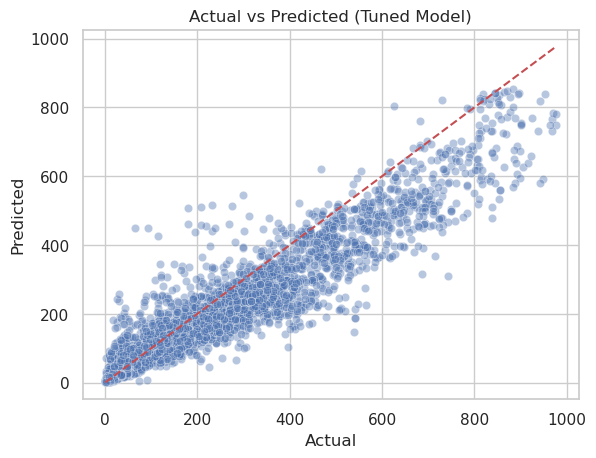

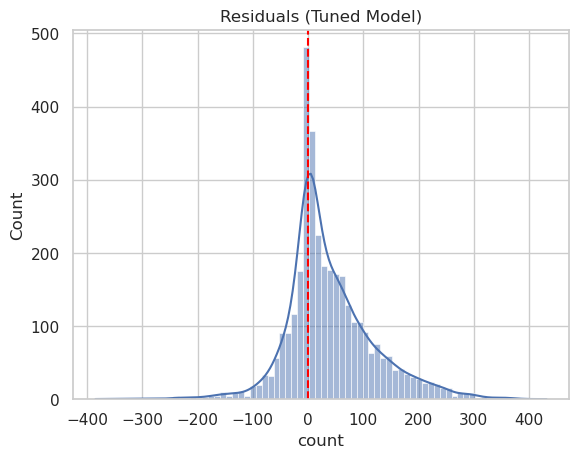

In [109]:
# Actual vs predicted
sns.scatterplot(x=Y_test, y=y_pred_tuned, alpha=0.4)
plt.plot([Y_test.min(), Y_test.max()], [Y_test.min(), Y_test.max()], '--r')
plt.title("Actual vs Predicted (Tuned Model)")
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.show()

# Residuals
residuals = Y_test - y_pred_tuned
sns.histplot(residuals, kde=True)
plt.title("Residuals (Tuned Model)")
plt.axvline(0, color='red', linestyle='--')
plt.show()


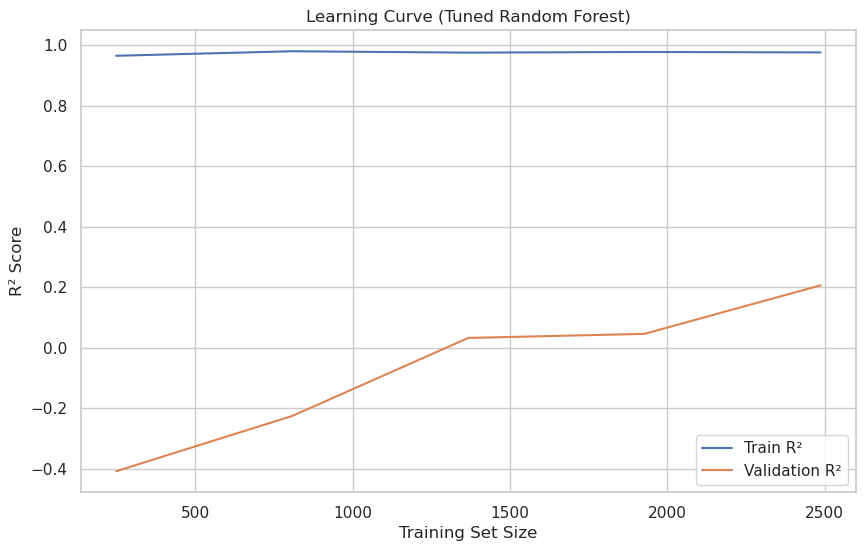

In [158]:
# Generate learning curve data
train_sizes, train_scores, test_scores = learning_curve(
    estimator=best_model,
    X=X,
    y=Y,
    train_sizes=np.linspace(0.1, 1.0, 5),
    cv=TimeSeriesSplit(n_splits=6),
    scoring='r2',
    n_jobs=-1
)

# Compute average scores
train_mean = np.mean(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)

# Plot the learning curve
plt.figure(figsize=(10, 6))
plt.plot(train_sizes, train_mean, label="Train R²")
plt.plot(train_sizes, test_mean, label="Validation R²")
plt.xlabel("Training Set Size")
plt.ylabel("R² Score")
plt.title("Learning Curve (Tuned Random Forest)")
plt.legend()
plt.grid(True)
plt.show()


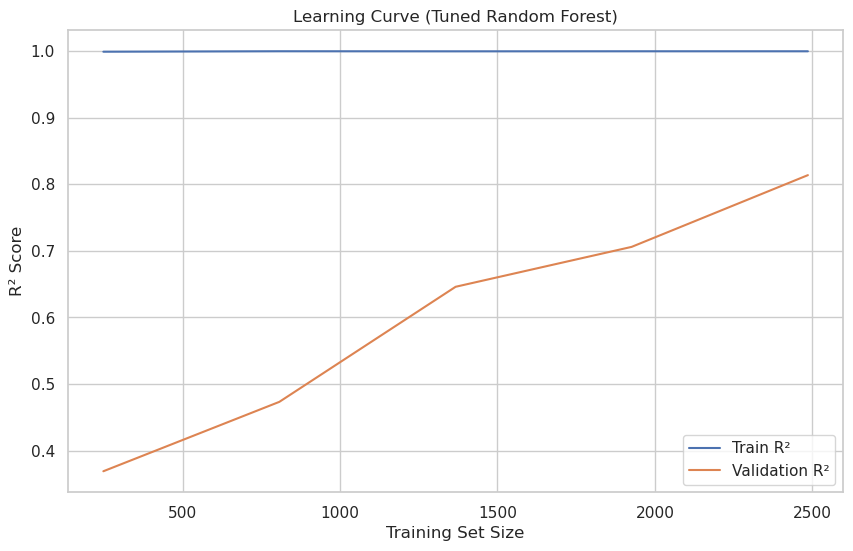

In [161]:
df_lagged = df.copy()
df_lagged['cnt_lag_1'] = df_lagged['count'].shift(1)
df_lagged = df_lagged.dropna().reset_index(drop=True)

X_lagged = df_lagged.drop(columns=['count'])
Y_lagged = df_lagged['count']



# Generate learning curve data
train_sizes, train_scores, test_scores = learning_curve(
    estimator=best_model,
    X=X_lagged,
    y=Y_lagged,
    train_sizes=np.linspace(0.1, 1.0, 5),
    cv=TimeSeriesSplit(n_splits=6),
    scoring='r2',
    n_jobs=-1
)

# Compute average scores
train_mean = np.mean(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)

# Plot the learning curve
plt.figure(figsize=(10, 6))
plt.plot(train_sizes, train_mean, label="Train R²")
plt.plot(train_sizes, test_mean, label="Validation R²")
plt.xlabel("Training Set Size")
plt.ylabel("R² Score")
plt.title("Learning Curve (Tuned Random Forest)")
plt.legend()
plt.grid(True)
plt.show()


To address low validation performance in the learning curve (especially with TimeSeriesSplit), we added a single engineered feature: cnt_lag_1, which represents the bike rental count from the previous hour.

This feature provided the model with temporal memory, allowing it to understand what happened just before the current time step. Since bike rental demand typically changes gradually (e.g., rising during rush hours or falling overnight), the previous hour’s count is often highly predictive of the current hour.

Before adding this feature, the model relied only on static inputs like hour, season, and weather — without any awareness of recent trends. As a result, it struggled to generalize, particularly in early training folds of TimeSeriesSplit, where little data was available. After adding cnt_lag_1, the model immediately gained context and was better equipped to make accurate predictions, even with smaller training sets.

The validation R² in the learning curve improved significantly, going from about 0.4 previously to over 0.8, and the gap between training and validation scores narrowed. This showed that the model was not only more accurate but also learning more effectively with increasing data — all from a single, intuitive feature.

## 6.Conclusion:
While the final model achieved strong performance — with an R² of 0.83 and an RMSE of approximately 89 — there remains room for improvement. If more time were available, the next step would be to engineer additional time-aware features, such as longer-range lags (e.g., 24-hour or 7-day lag), rolling averages, and demand deltas. These could help the model better capture patterns like weekly seasonality and gradual demand shifts.

Furthermore, experimenting with advanced models such as XGBoost or LightGBM could enhance predictive accuracy and reduce overfitting. These models often outperform Random Forests on structured data, especially when combined with well-crafted features. Additionally, applying log-transformation to the target variable or performing Bayesian hyperparameter optimization may further improve generalization.

Lastly, incorporating external data — such as special events, holidays, or traffic — could provide more context to the model and help explain unexpected fluctuations in demand. Overall, while the current model performs well, combining deeper feature engineering with more powerful algorithms would likely yield even stronger results.

In [165]:
import json

def count_words_in_notebook(path):
    with open(path, 'r', encoding='utf-8') as f:
        notebook = json.load(f)

    word_count = 0

    for cell in notebook['cells']:
        # Count words in Markdown cells
        if cell['cell_type'] == 'markdown':
            text = ''.join(cell['source'])
            word_count += len(text.split())

    return word_count

notebook_path = 'FinalProj.ipynb'
total_words = count_words_in_notebook(notebook_path)
print(f"Total word count (markdown only): {total_words}")


Total word count (markdown only): 2294
